###Bước 1) Đọc và chuẩn bị dữ liệu

In [1]:
def in_thong_tin():
    print("Họ và tên: Nguyễn Gia Huy")
    print("Mã sinh viên: 6451071027")
    print("-" * 30)

in_thong_tin()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.datasets import mnist
from sklearn.cluster import KMeans

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

# Chuẩn hóa [0,1] và làm phẳng 28x28 -> 784
X = train_images.reshape(len(train_images), -1) / 255.0
y = train_labels

print("Ảnh gốc    :", train_images.shape)
print("Dữ liệu X  :", X.shape)       # (60000, 784)
print("Nhãn y     :", y.shape)
print("Min/Max X  :", X.min(), X.max())

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Ảnh gốc    : (60000, 28, 28)
Dữ liệu X  : (60000, 784)
Nhãn y     : (60000,)
Min/Max X  : 0.0 1.0


###Bước 2) Gom cụm bằng k-Means (k = 10)

In [2]:
in_thong_tin()

kmeans = KMeans(n_clusters=10, n_init=10, random_state=42)
kmeans.fit(X)

cum = kmeans.labels_            # cụm của từng ảnh
tam_cum = kmeans.cluster_centers_

print("Số ảnh trong mỗi cụm:")
print(pd.Series(cum).value_counts().sort_index().to_string())
print("Inertia:", kmeans.inertia_)

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Số ảnh trong mỗi cụm:
0    5720
1    5966
2    6526
3    4679
4    3178
5    5592
6    8855
7    8934
8    7454
9    3096
Inertia: 2352826.6299970257


###Bước 3) Hiển thị tâm của 10 cụm dưới dạng ảnh

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


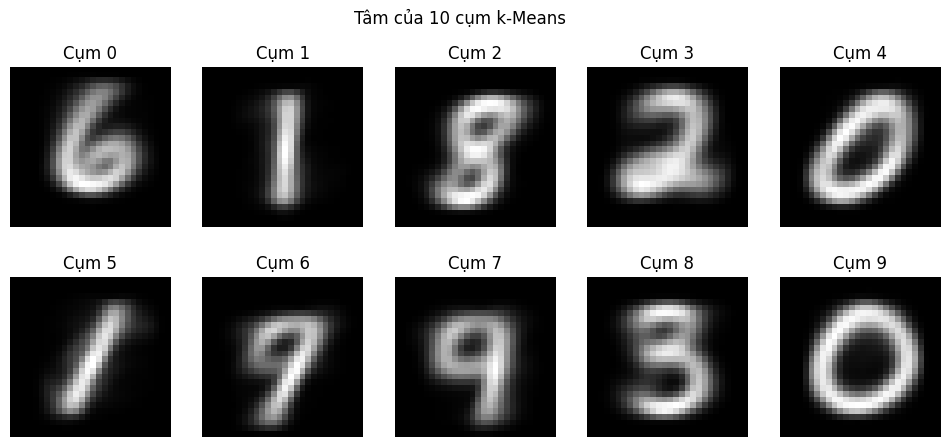

In [3]:
in_thong_tin()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(tam_cum[i].reshape(28, 28), cmap='gray')
    ax.set_title(f'Cụm {i}')
    ax.axis('off')
plt.suptitle('Tâm của 10 cụm k-Means')
plt.show()

###Bước 4) Bảng đối chiếu cụm với nhãn thực tế

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Nhãn thực     0     1     2     3     4     5     6     7     8     9
Cụm                                                                  
0           182     9   212    57   165   123  4913     4    47     8
1             3  3717   364   426   159   164   271   327   296   239
2           180    10   158  1039    19  1494    91    10  3456    69
3            17     9  4193   215    38    15    87    38    54    13
4          2497     0   101   126    11   256   121    15    32    19
5            21  2977   351   103   309   793   223   282   417   116
6            14     9    69    50  1941   357     1  3773   181  2460
7            38     6   173   175  3189   379    82  1796   193  2903
8           163     5   327  3925     1  1778    28     5  1137    85
9          2808     0    10    15    10    62   101    15    38    37


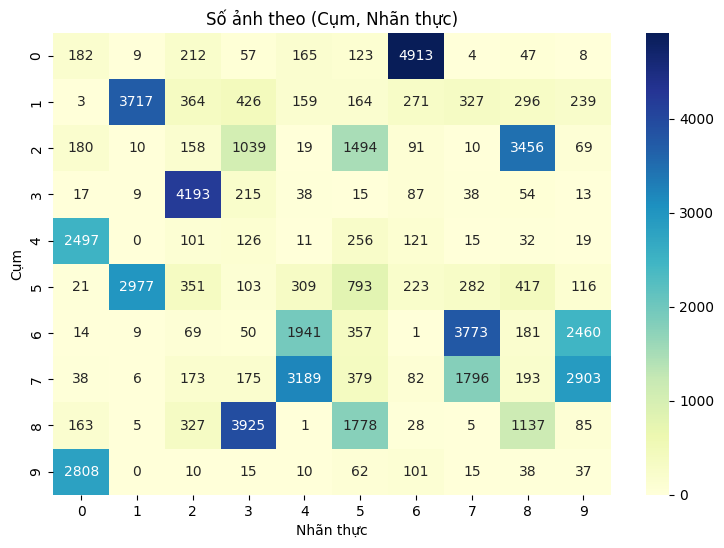

In [4]:
in_thong_tin()

bang = pd.crosstab(cum, y, rownames=['Cụm'], colnames=['Nhãn thực'])
print(bang)

plt.figure(figsize=(9, 6))
sns.heatmap(bang, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Số ảnh theo (Cụm, Nhãn thực)')
plt.show()

###Bước 5) Gán nhãn cho từng cụm theo đa số và tính độ thuần khiết

In [5]:
in_thong_tin()

# Gán nhãn đa số cho từng cụm
anh_xa = {c: np.bincount(y[cum == c]).argmax() for c in range(10)}
y_pred = np.array([anh_xa[c] for c in cum])

ket_qua = []
for c in range(10):
    so_anh = (cum == c).sum()
    dung = (y[cum == c] == anh_xa[c]).sum()
    ket_qua.append([c, anh_xa[c], so_anh, dung, dung / so_anh])

df_cum = pd.DataFrame(ket_qua, columns=['Cụm', 'Chữ số đại diện', 'Số ảnh', 'Số ảnh đúng', 'Độ thuần khiết'])
print(df_cum.round(4).to_string(index=False))
print("\nCác chữ số không được cụm nào đại diện:",
      sorted(set(range(10)) - set(anh_xa.values())))

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
 Cụm  Chữ số đại diện  Số ảnh  Số ảnh đúng  Độ thuần khiết
   0                6    5720         4913          0.8589
   1                1    5966         3717          0.6230
   2                8    6526         3456          0.5296
   3                2    4679         4193          0.8961
   4                0    3178         2497          0.7857
   5                1    5592         2977          0.5324
   6                7    8855         3773          0.4261
   7                4    8934         3189          0.3570
   8                3    7454         3925          0.5266
   9                0    3096         2808          0.9070

Các chữ số không được cụm nào đại diện: [5, 9]


###Bước 6) Đánh giá tổng thể kết quả gom cụm so với nhãn

In [6]:
in_thong_tin()
from sklearn.metrics import (accuracy_score, classification_report,
                             adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score)

print("Accuracy (cụm -> nhãn đa số):", round(accuracy_score(y, y_pred), 4))
print("Adjusted Rand Index (ARI)    :", round(adjusted_rand_score(y, cum), 4))
print("Normalized Mutual Info (NMI) :", round(normalized_mutual_info_score(y, cum), 4))
print("Homogeneity                  :", round(homogeneity_score(y, cum), 4))
print("Completeness                 :", round(completeness_score(y, cum), 4))

print("\nPrecision, Recall, F1-score từng chữ số:")
print(classification_report(y, y_pred, digits=4, zero_division=0))

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Accuracy (cụm -> nhãn đa số): 0.5908
Adjusted Rand Index (ARI)    : 0.3607
Normalized Mutual Info (NMI) : 0.4906
Homogeneity                  : 0.485
Completeness                 : 0.4964

Precision, Recall, F1-score từng chữ số:
              precision    recall  f1-score   support

           0     0.8456    0.8957    0.8699      5923
           1     0.5792    0.9929    0.7316      6742
           2     0.8961    0.7038    0.7884      5958
           3     0.5266    0.6402    0.5778      6131
           4     0.3570    0.5459    0.4316      5842
           5     0.0000    0.0000    0.0000      5421
           6     0.8589    0.8302    0.8443      5918
           7     0.4261    0.6022    0.4991      6265
           8     0.5296    0.5907    0.5585      5851
           9     0.0000    0.0000    0.0000      5949

    accuracy                         0.5908     60000
   macro avg     0.5019    0.5801    0

###Bước 7) Confusion matrix sau khi ánh xạ cụm sang nhãn

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


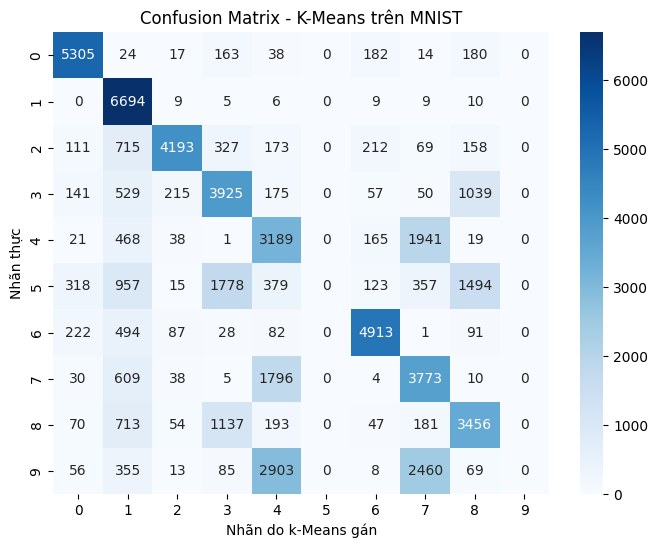

In [7]:
in_thong_tin()
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Nhãn do k-Means gán'); plt.ylabel('Nhãn thực')
plt.title('Confusion Matrix - K-Means trên MNIST')
plt.show()

###Bước 8) Xem mẫu ảnh của từng cụm

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


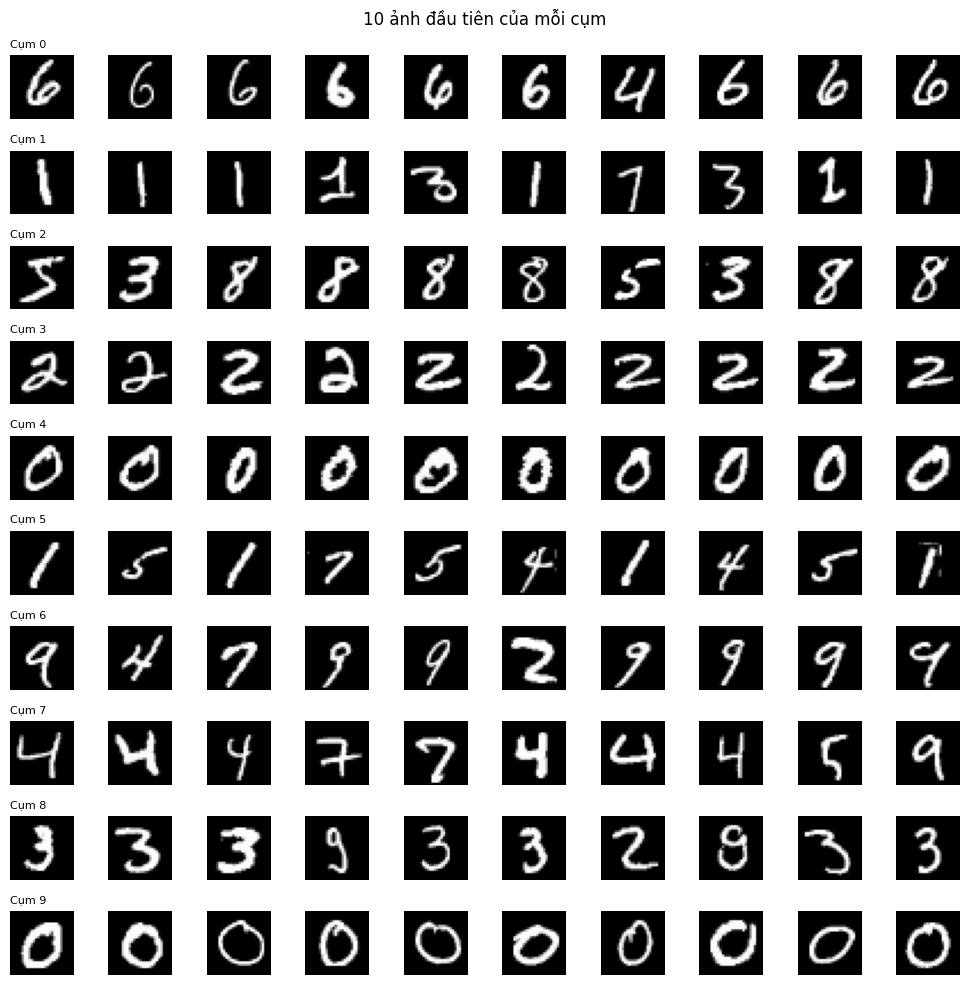

In [8]:
in_thong_tin()

fig, axes = plt.subplots(10, 10, figsize=(10, 10))
for c in range(10):
    idx = np.where(cum == c)[0][:10]
    for j in range(10):
        ax = axes[c, j]
        ax.axis('off')
        if j < len(idx):
            ax.imshow(train_images[idx[j]], cmap='gray')
            if j == 0:
                ax.set_title(f'Cụm {c}', fontsize=8, loc='left')
plt.suptitle('10 ảnh đầu tiên của mỗi cụm')
plt.tight_layout()
plt.show()